# Predicting Treatment-Seeking in Tech: Logistic Regression
**Question:** Which survey-reported workplace and personal factors predict whether a tech worker has sought mental health treatment?

**Data:** OSMI Mental Health in Tech survey (~1,100 responses after cleaning), 10 encoded features, 70/30 train/test split (`random_state=42`), balanced classes.

**Result:** Baseline logistic regression reaches ~69% test accuracy (precision and recall ~0.69 for both classes). Family history is the strongest positive predictor.

**Scope:** This notebook is my portion of a team project that also compared random forest and XGBoost models.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
pd.set_option("display.max_columns", None)
data = pd.read_csv("../data/survey.csv")
data.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,No,Yes,Yes,Not sure,No,Yes,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,No,No,Don't know,No,Don't know,Don't know,Don't know,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,No,Yes,No,No,No,No,Don't know,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,No,Yes,No,Yes,No,No,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,Yes,Yes,Yes,No,Don't know,Don't know,Don't know,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In [ ]:
data_clean = pd.read_csv("../data/encoded_survey_data.csv")
data_clean.head()

,Gender,benefits,care_options,anonymity,leave,work_interfere,family_history,no_employees_encoded,age_scaled_standard,support_supervisor_resources,treatment
0,0,2,1,2,2,1,0,2,0.700373,1,1
1,1,0,0,0,0,2,0,6,1.658007,0,0
2,1,1,0,0,1,2,0,2,0.016348,0,0
3,1,1,2,1,1,1,1,3,-0.120457,0,1
4,1,2,0,0,0,0,0,4,-0.120457,0,0


## Run Logistic Regression w/out Regularization

In [ ]:
# Separate features and label
X = data_clean.drop("treatment", axis=1)  # all columns except 'treatment'
y = data_clean["treatment"]  # just the 'treatment' column

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# check the shapes
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(779, 10) (334, 10) (779,) (334,)


In [ ]:
model = LogisticRegression(
    max_iter=1000
)  # iteration is roughly one update step, not exactly a full epoch
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
# Predict on test set
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

# Detailed classification report
class_report = classification_report(y_test, y_pred)
print("Classification Report:\n", class_report)

Accuracy: 0.6946107784431138
Confusion Matrix:
 [[120  50]
 [ 52 112]]
Classification Report:
               precision    recall  f1-score   support

           0       0.70      0.71      0.70       170
           1       0.69      0.68      0.69       164

    accuracy                           0.69       334
   macro avg       0.69      0.69      0.69       334
weighted avg       0.69      0.69      0.69       334



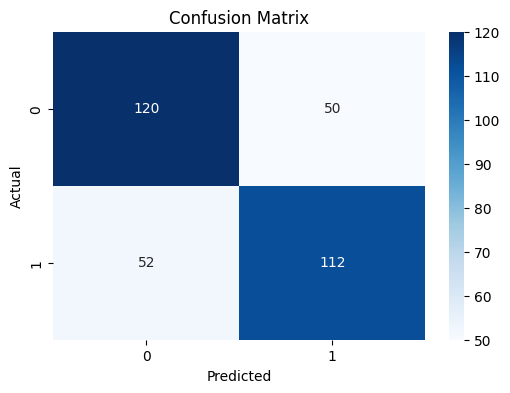

In [ ]:
# Plot
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("../figures/logreg_conf_base.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Model coefficients (features are encoded, so read magnitudes with care)
coef_df = pd.DataFrame(
    {"Feature": X.columns, "Coefficient": model.coef_[0]}
).sort_values(by="Coefficient", ascending=False)

print(coef_df)

                        Feature  Coefficient
6                family_history     1.717648
2                  care_options     0.367240
1                      benefits     0.314448
3                     anonymity     0.208531
8           age_scaled_standard     0.183425
4                         leave     0.019570
5                work_interfere    -0.061081
7          no_employees_encoded    -0.091159
9  support_supervisor_resources    -0.574622
0                        Gender    -0.720288


In [ ]:
# Plot coefficients: sign shows direction, size shows relative effect per encoded unit
plt.figure(figsize=(10, 6))
plt.barh(coef_df["Feature"], coef_df["Coefficient"])
plt.title("Logistic Regression Coefficients (encoded features)")
plt.xlabel("Coefficient Value")
plt.savefig("../figures/logreg_features.png", dpi=300, bbox_inches="tight")
plt.show()

**Note on interpretation and fairness.** Coefficients are for ordinal/label-encoded features, so their sizes depend on how each variable was coded and should not be read as feature importance. `Gender` carries one of the largest coefficients (negative); it is kept here to describe patterns in this survey, but a model like this should not be used to make decisions about individuals, and a protected attribute would normally be reviewed (or excluded) before any real-world use.

In [ ]:
print("Converged in", model.n_iter_[0], "iterations")

Converged in 31 iterations


## Check Whether Regularization Helps
Tune the L2 regularization strength `C` with 5-fold cross-validation on the training set only, then compare test accuracy to the unregularized baseline. If accuracy is unchanged, keep the simpler unregularized model.

In [ ]:
# Tune C (inverse regularization strength) for an L2 penalty
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(
    LogisticRegression(penalty="l2", solver="saga", max_iter=5000, random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy",
)
grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print("Best CV accuracy:", round(grid_search.best_score_, 4))

In [ ]:
# Refit is done by GridSearchCV; use the best estimator found above
model_reg = grid_search.best_estimator_
model_reg

In [ ]:
# Compare regularized vs. baseline on the held-out test set
y_pred_reg = model_reg.predict(X_test)

print(
    "Baseline test accuracy:   ",
    round(accuracy_score(y_test, model.predict(X_test)), 4),
)
print("Regularized test accuracy:", round(accuracy_score(y_test, y_pred_reg), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_reg))
print("Classification Report:\n", classification_report(y_test, y_pred_reg))